# 优化 Syn2-重新设计数据结构

In [ ]:
import numpy as np
from TDD.TDD import TDD, Ini_TDD,Clear_TDD,set_index_order,get_unique_table_num,set_root_of_unit,get_count,cont,renormalize,Slicing2,Slicing
from TDD.TDD_Q import cir_2_tn,get_real_qubit_num,add_trace_line,add_inputs,add_outputs,gen_cir
from TDD.TN import Index,Tensor,TensorNetwork
from TDD.Syn import *
import time
import random
from qiskit import QuantumCircuit,qasm2
import cProfile
from IPython.display import display, HTML,Image
# from PIL import Image
from PIL import Image as PILImage
import networkx as nx
import copy
from qiskit.circuit.library.standard_gates import HGate,U1Gate,U3Gate
from qiskit.quantum_info.operators import Operator
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector
from qiskit.circuit import CircuitInstruction

import itertools

to_test = False

import warnings

warnings.simplefilter("ignore")

In [64]:
def change_tdd_2_vec(tdd):
    n = tdd.node.key+1
    tdd_new = tdd.self_copy()
    tdd_new.key_2_index = {-1:-1}
    tdd_new.index_set = []
    for k in range(n):
        tdd_new.index_set.append(Index('y'+str(k),0))
        tdd_new.key_2_index[k] = 'y'+str(k)
    tdd_new.index_2_key = {tdd_new.key_2_index[a]:a for a in tdd_new.key_2_index} 
    return tdd_new
    
def to_zero_state(tdd,reduce=False):
    n = tdd.node.key+1
    cir_head = Circuit(n,[])
    cir_end = Circuit(n,[])   
    tdd_new = change_tdd_2_vec(tdd)
    cir_end2 = eliminate_global_map(tdd_new)
    cir_end.data+=cir_end2.data
    # print(cir_end)
    # print('aa')
    # cir_end2 = eliminate_border_control(tdd_new)
    # cir_end=cir_end&cir_end2
    cir_end2 = eliminate_border_control_x(tdd_new)
    if reduce:
        cir_end2 = reduce_a_block(cir_end2)
    cir_end.data+=cir_end2.data
    # print(cir_end)
    cir_end2 = eliminate_border_control_p(tdd_new)
    if reduce:
        cir_end2 = reduce_a_block(cir_end2)    
    cir_end.data+=cir_end2.data
    # print(cir_end)
    # print('bb')
    cir_end2,_ = eliminate_weight(tdd_new)
    H = 1/np.sqrt(2)*np.array([[1,1],[1,-1]])
    # u3 = UnitaryGate(H)
    for k in range(n//2):
        # cir_end2.append(u3,[2*k+1])
        cir_end2.data.append(Gate('u',{},2*k+1,H))
        
    if reduce:
        cir_end2 = reduce_a_block(cir_end2)    
    cir_end.data+=cir_end2.data
    # print('cc')
    for k in range(n//2):
        # cir_end.h(2*k+1)
        # cir_end.cx(2*k+1,2*k)
        cir_end.data.append(Gate('x',{2*k+1:1},2*k))
    # print('dd')
    # tdd_new = update_tdd(tdd_new,cir_head,cir_end)
    # print('ee')
    return tdd_new,cir_end

In [65]:
def swap_two_gate(n,g0,g1):
    "g0在左，g1在右"
    cir_temp = Circuit(n,[])
    
    # 控制条件相同
    if g0.q_c==g1.q_c and g0.q_t==g1.q_t:
        if np.allclose(np.dot(g1.para,g0.para),np.eye(2)):# 两门刚好互逆可消
            return cir_temp,True
        else:
            u = np.dot(g1.para,g0.para)
            g = Gate(g0.name,g0.q_c,g0.q_t,u)
            cir_temp.data=[g]
            return cir_temp,True
        
    #某处控制条件不同:
    com_q_c = [k for k in g0.q_c if k in g1.q_c]
    c = [abs(g0.q_c[k]-g1.q_c[k]) for k in com_q_c]

####-----------处理特殊情况

    if 'x' in g0.name and 'x' in g1.name:
        if sum(c)==2 and set(g0.q_c.keys())==set(g1.q_c.keys()) and g0.q_t==g1.q_t: #都是x,某两处控制条件不同
            p0 = c.index(1)
            p1 = p0+1+c[p0+1:].index(1)
            cond0={p0:1}
            cond1={p1:1}
            for k in g0.q_c:
                if k!=p0 and k!=p1:
                    cond0[k] = g0.q_c[k]
                    cond1[k] = g0.q_c[k]
            g00 = Gate('x',cond0,g0.q_t,g0.para)
            g11 = Gate('x',cond1,g1.q_t,g1.para)
            cir_temp.data.append(g00)
            cir_temp.data.append(g11)
            if g0.q_c[com_q_c[p0]]==g0.q_c[com_q_c[p1]]:
                g = Gate('x',{},g1.q_t,g1.para)
                cir_temp.data.append(g)
            return cir_temp,True
        # if len(g0.q_c)==len(g1.q_c)==1:
        #     if g0.q_t in g1.q_c:
        #         cir_temp.data.append(g1)
        #         g = Gate('x',g0.q_c,g1.q_t)
        #         cir_temp.data.append(g)
        #         cir_temp.data.append(g0)
        #         return cir_temp,True
        #     if g1.q_t in g0.q_c:
        #         cir_temp.data.append(g1)
        #         g = Gate('x',g1.q_c,g0.q_t)
        #         cir_temp.data.append(g)
        #         cir_temp.data.append(g0)
        #         return cir_temp,True
                
    Z=np.array([[1,0],[0,-1]])
    if 'p' in g0.name and 'p' in g1.name:
        if sum(c)==2 and set(g0.q_c.keys())==set(g1.q_c.keys()) and g0.q_t==g1.q_t and np.allclose(g0.para,Z) and np.allclose(g1.para,Z): #都是p,某两处控制条件不同
            p0 = c.index(1)
            p1 = p0+1+c[p0+1:].index(1)
            cond0={p0:1}
            cond1={p1:1}
            for k in g0.q_c:
                if k!=p0 and k!=p1:
                    cond0[k] = g0.q_c[k]
                    cond1[k] = g0.q_c[k]
            g00 = Gate('p',cond0,g0.q_t,g0.para)
            g11 = Gate('p',cond1,g1.q_t,g1.para)
            cir_temp.data.append(g00)
            cir_temp.data.append(g11)
            if g0.q_c[com_q_c[p0]]==g0.q_c[com_q_c[p1]]:
                g = Gate('p',{},g1.q_t,g1.para)
                cir_temp.data.append(g)
            return cir_temp,True
            
    if 'x' in g0.name and 'p' in g1.name and np.allclose(g1.para,Z) and len(g0.q_c)==len(g1.q_c)==1 and g1.q_t in g0.q_c:
        cir_temp.data.append(g1)
        g = Gate('p',{},g1.q_t,Z)
        cir_temp.data.append(g0)
        return cir_temp,True
    if 'x' in g1.name and 'p' in g0.name and np.allclose(g0.para,Z) and len(g0.q_c)==len(g1.q_c)==1 and g0.q_t in g1.q_c:
        cir_temp.data.append(g1)
        g = Gate('p',{},g0.q_t,Z)
        cir_temp.data.append(g0)
        return cir_temp,True

####-----------处理一般情况
    
    #仅控制比特相交或完全不相交
    if g0.q_t!=g1.q_t and not g0.q_t in g1.q_c and not g1.q_t in g0.q_c:
        cir_temp.data = [g1,g0]
        return cir_temp,True
    
    if sum(c)>1:#某处控制条件不同
        if sum(c)==1 and set(g0.q_c.keys())==set(g1.q_c.keys()) and g0.q_t==g1.q_t and np.allclose(g0.para,g1.para):#比特相同，某一处控制条件不同
            q = [k for k in g0.q_c]
            q.pop(com_q_c[c.index(1)])
            cond = {k:g0.q_c[k] for k in q}
            g = Gate(g0.name,cond,g0.q_t,g0.para)
            cir_temp.data.append(g)
            return cir_temp,True
        cir_temp.data = [g1,g0]
        return cir_temp,True
        
    if g0.q_t==g1.q_t and np.allclose(g0.para,g1.para) and np.allclose(np.dot(g0.para,g0.para),np.eye(2)):
        if len(g0.q_c)==len(g1.q_c)+1: #控制条件相同但差一个比特
            q = [k for k in g0.q_c]
            cond={}
            for k in q:
                if k in g1.q_c:
                    cond[k] = g0.q_c[k]
                else:
                    cond[k] = 1-g0.q_c[k]
            g = Gate(g0.name,cond,g0.q_t,g0.para)
            cir_temp.data.append(g)
            return cir_temp,True
        if len(g1.q_c)==len(g0.q_c)+1: #控制条件相同但差一个比特
            q = [k for k in g1.q_c]
            cond={}
            for k in q:
                if k in g0.q_c:
                    cond[k] = g1.q_c[k]
                else:
                    cond[k] = 1-g1.q_c[k]
            g = Gate(g1.name,cond,g1.q_t,g1.para)
            cir_temp.data.append(g)
            return cir_temp,True
            
    if set(g0.q_c.keys()).issubset(set(g1.q_c.keys())):
        u = np.dot(g1.para,np.dot(g0.para,g1.para.T.conj()))
        g = Gate(g1.name,g1.q_c,g1.q_t,u)
        cir_temp.data = [g1,g]
        return cir_temp,True
    
        
    cir_temp.data = [g0,g1]
    return cir_temp,False

# cc = QuantumCircuit(5)

# cc.mcp(np.pi,[3],2,ctrl_state = '1')
# cc.mcp(np.pi,[4,3],2,ctrl_state = '11')
# print(cc)
# c,res = swap_two_gate(5,cc.data[0],cc.data[1])
# print(res)
# c.draw('mpl')

In [66]:
def to_H_Graph(cir):
    n=cir.num_qubits
    G = H_Graph(n)
    end_nodes = {}
    for k in range(n):
        node = Node_P(k,0)
        node.eig_direction=np.array([1,0])
        G.start_nodes[k] = node
        end_nodes[k] = node
        
    for g in cir.data:
        g.nodes = {}
        for k in g.q_c:
            if np.allclose(end_nodes[k].eig_direction,np.array([1,0])) and end_nodes[k]!=G.start_nodes[k]:
                end_nodes[k].gates.append(g)
            else:
                node = Node_P(k,end_nodes[k].pos+1)
                node.eig_direction=np.array([1,0])
                node.gates.append(g)
                end_nodes[k].successor = node
                node.predecessor = end_nodes[k]
                end_nodes[k] = node
                G.nodes.append(node)
            g.nodes[k] = end_nodes[k]
        k = g.q_t
        res = np.dot(g.para,end_nodes[k].eig_direction)
        if np.allclose(res,sum(res)/sum(end_nodes[k].eig_direction)*end_nodes[k].eig_direction) and end_nodes[k]!=G.start_nodes[k]:
            end_nodes[k].gates.append(g)
        else:
            node = Node_P(k,end_nodes[k].pos+1)
            if g.name == 'p':
                eig_v = np.array([1,0])
            elif g.name=='x':
                eig_v = np.array([1,1])
            else:
                eig_va, eig_vc = np.linalg.eig(g.para)
                eig_v = eig_vc[0]
            node.eig_direction = eig_v
            node.gates.append(g)
            end_nodes[k].successor = node
            node.predecessor = end_nodes[k]
            end_nodes[k] = node
            G.nodes.append(node)
        g.nodes[k] = end_nodes[k]
        G.gates.append(g)
        
    for k in range(n):
        node = Node_P(k,end_nodes[k].pos+1)
        node.eig_direction=np.array([1,0])
        G.end_nodes[k] = node
        end_nodes[k].successor = node
        node.predecessor = end_nodes[k]
        
    return G
    
def opt_H_Graph(G):
    node_copy = copy.copy(G.nodes)
    for node in node_copy:
        if np.allclose(node.eig_direction,np.array([1,1])) and len(node.gates)>1: #处理X的情况
            for (a,b) in itertools.combinations(node.gates, 2):
                if len(a.q_c)!=1:
                    continue
                if len(b.q_c)!=1:
                    continue
                q_ca = list(a.q_c.keys())[0]
                q_cb = list(b.q_c.keys())[0]
                g0 = Gate('x',a.q_c,q_cb)
                g1 = Gate('x',b.q_c,q_ca)
                if g0 in a.nodes[q_ca].gates:
                    q_t = g0.q_t
                    g0 = a.nodes[q_ca].gates[a.nodes[q_ca].gates.index(g0)]
                    if b.nodes[q_cb].successor==g0.nodes[q_t]:
                        a.nodes[q_ca].gates.remove(a)
                        node.gates.remove(a)
                        new_node = Node_P(q_t,-1)
                        new_node.eig_direction = np.array([1,0])
                        new_node.gates = [b]
                        b.nodes[q_t].gates.remove(b)
                        b.nodes[q_t] = new_node
                        new_node.successor = g0.nodes[q_t].successor
                        g0.nodes[q_t].successor.predecessor = new_node
                        new_node.predecessor = g0.nodes[q_t]
                        g0.nodes[q_t].successor = new_node
                        break
                    elif b.nodes[q_cb].predecessor==g0.nodes[g0.q_t]:
                        a.nodes[q_ca].gates.remove(a)
                        node.gates.remove(a)
                        new_node = Node_P(g0.q_t,-1)
                        new_node.eig_direction = np.array([1,0])
                        new_node.gates = [b]
                        b.nodes[q_t].gates.remove(b)
                        b.nodes[g0.q_t] = new_node
                        new_node.predecessor = g0.nodes[q_t].predecessor
                        g0.nodes[q_t].predecessor.successor = new_node
                        new_node.successor = g0.nodes[q_t]
                        g0.nodes[q_t].predecessor = new_node
                        break
                elif g1 in b.nodes[q_cb].gates:
                    q_t = g1.q_t
                    g1 = b.nodes[q_cb].gates[b.nodes[q_cb].gates.index(g1)]
                    if a.nodes[q_ca].successor==g1.nodes[q_t]:
                        b.nodes[q_cb].gates.remove(b)
                        node.gates.remove(b)
                        new_node = Node_P(q_t,-1)
                        new_node.eig_direction = np.array([1,0])
                        new_node.gates = [a]
                        a.nodes[q_t].gates.remove(a)
                        a.nodes[q_t] = new_node
                        new_node.successor = g1.nodes[q_t].successor
                        g1.nodes[q_t].successor.predecessor = new_node
                        new_node.predecessor = g1.nodes[q_t]
                        g1.nodes[q_t].successor = new_node
                        break
                    elif a.nodes[q_ca].predecessor==g1.nodes[g1.q_t]:
                        b.nodes[q_cb].gates.remove(b)
                        node.gates.remove(b)
                        new_node = Node_P(g1.q_t,-1)
                        new_node.eig_direction = np.array([1,0])
                        new_node.gates = [a]
                        a.nodes[q_t].gates.remove(a)
                        a.nodes[g1.q_t] = new_node
                        new_node.predecessor = g1.nodes[q_t].predecessor
                        g1.nodes[q_t].predecessor.successor = new_node
                        new_node.successor = g1.nodes[q_t]
                        g1.nodes[q_t].predecessor = new_node
                        break
    return G

def H_Graph_to_Cir(G):
    cir = Circuit(G.num_qubits,[])
    is_empty = False
    while(not is_empty):
        is_empty = True
        for k in range(G.num_qubits):
            if G.start_nodes[k].successor!=G.end_nodes[k]:
                is_empty = False
                break
        if is_empty:
            break
        for k in range(G.num_qubits):
            node = G.start_nodes[k].successor
            # print(node)
            if node==G.end_nodes[k]:
                continue
            new_gates = []
            for g in node.gates:
                is_leftmost = True
                for nn in g.nodes.values():
                    if not nn.predecessor in G.start_nodes.values():
                        is_leftmost=False
                if is_leftmost:
                    # print(g)
                    cir.data.append(g)
                    for nn in g.nodes.values():
                        if not nn==node:
                            nn.gates.remove(g)
                else:
                    new_gates.append(g)
            if len(new_gates)==0:
                G.start_nodes[k].successor = node.successor
                node. successor.predecessor = G.start_nodes[k]
            else:
                node.gates = new_gates
    return cir
# def extract_normal_gate(G):
#     pass
# def modify_qubits(G):
#     pass

# A = np.array([[0, 1], [1, 0]])
# eigenvalues, eigenvectors = np.linalg.eig(A)
# print("特征值:", eigenvalues)
# print("特征向量:", eigenvectors[0])

In [67]:
def reduce_a_block(cir):
    n2 = cir.num_qubits
    cir_l = Circuit(n2,[])
    for g in cir.data:
        cir_t,res = swap_a_gate_to_head(cir_l,g)
        cir_l = cir_t
    return cir_l

def to_normal_gate(g,cir_head,cir_end):
    """0->x;1->y"""
    q_c_n = {k//2:g.q_c[k] for k in g.q_c}
    g_n = Gate(g.name,q_c_n,g.q_t//2,g.para)           
    if g.q_t%2==0:
        cir_head.data.insert(0,g_n)
    else:
        cir_end.data.append(g_n)
    return cir_head,cir_end


def swap_a_gate_to_head(cir_l,g):
    n=cir_l.num_qubits
    cir_new = Circuit(n,[])
    if len(cir_l.data)==0:
        cir_new.data.append(g)
        return cir_new,True
    for k in range(len(cir_l.data)-1,-1,-1):
        # print(cir_l.data[k],g)
        cir_t,res = swap_two_gate(n,cir_l.data[k],g)
        # if len(cir_t.data)==3: #如果引入了更多的门，而新引入的门不能在未来被消掉，则放弃这次交换
        #     if not cir_t[0] in cir_l.data[:k] and not cir_t[1] in cir_l.data[:k]:
        #         cir_t = Circuit(n,[])
        #         cir_t.data.append(cir_l.data[k])
        #         cir_t.data.append(g)
        #         res = False
                
        if not res:
            cir_new.data=cir_l.data[:k]+cir_t.data+cir_new.data
            return cir_new,res
        if k!=0:
            if len(cir_t.data)==0:
                cir_new.data = cir_l.data[:k]+cir_new.data
                break
            g = cir_t.data.pop(0)
        cir_new.data = cir_t.data+cir_new.data
    return cir_new,True


def get_exg_processable(cir):
    n=cir.num_qubits//2
    cir_head = Circuit(n,[])
    cir_end = Circuit(n,[])
    n2 = cir.num_qubits
    cir_l = Circuit(n2,[])
    for g in cir.data:
        q = g.qubits()
        q_b = [k%2 for k in q]
        if all(k == q_b[0] for k in q_b):#是正常门
            cir_t,res = swap_a_gate_to_head(cir_l,g)
        else:
            cir_l.data.append(g)
            continue
        # cir_t,res = swap_a_gate_to_head(cir_l,g)
        # print(g,cir_l,cir_t)
        # if len(cir_t.data)>len(cir_l.data)+2:  #如果交换引入了太多新门，就放弃此次交换
        #     cir_l.data = cir_l.data+[g]
        #     continue
        if len(cir_t.data)>0:
            q = cir_t.data[0].qubits()
            q_b = [k%2 for k in q]
            if all(k == q_b[0] for k in q_b):#是正常门
                # print(q,q_b,g)
                cir_head,cir_end = to_normal_gate(cir_t.data[0],cir_head,cir_end)
                cir_t.data.pop(0)
            cir_l = cir_t
        else:
            cir_l = cir_t
    return cir_l,cir_head,cir_end

def swap_a_gate_to_end(cir_r,g):
    n=cir_r.num_qubits
    cir_new = Circuit(n,[])
    if len(cir_r.data)==0:
        cir_new.data+=[g]
        return cir_new,Circuit(n,[]),True
    for k in range(len(cir_r.data)):
        cir_t,res = swap_two_gate(n,g,cir_r.data[k])
        # print(k,g,cir_t)
        # print('----------------')
        if len(cir_t.data)==3: #如果引入了更多的门，而新引入的门不能在未来被消掉，则放弃这次交换
            if not cir_t.data[2] in cir_r.data[k+1:] and not cir_t.data[1] in cir_r.data[k+1:]:
                cir_t = Circuit(n,[])
                cir_t.data.append(g)
                cir_t.data.append(cir_r.data[k])
                res = False
        if len(cir_t.data)==4: #如果引入了更多的门，而新引入的门不能在未来被消掉，则放弃这次交换
                cir_t = Circuit(n,[])
                cir_t.data.append(g)
                cir_t.data.append(cir_r.data[k])
                res = False
        if not res:
            cir_new.data=cir_new.data + cir_t.data[:1]    
            cir_r2 = Circuit(n,[])
            cir_r2.data = cir_t.data[1:]+cir_r.data[k+1:]
            return cir_new,cir_r2,res

        if k!=len(cir_r.data)-1:
            if len(cir_t.data)==0:
                cir_r2 = Circuit(n,[])
                cir_r2.data = cir_r.data[k+1:]
                # cir_new.id(0)
                id = Gate('id',{},0)
                return cir_new,cir_r2,True
            g = cir_t.data.pop(-1)
        cir_new.data = cir_new.data+cir_t.data
    return cir_new,Circuit(n,[]),True

def modify_qubits_of_a_gate(g,cir_r):

    global like_x
    
    # cir_t2 = QuantumCircuit(n)
    # cir_t2.data = [g]    
    # cir_r2 = QuantumCircuit(n)
    # cir_r2.data = cir_t.data[1:]+cir_r.data[k+1:]

    # for g in cir_r2.data:
    #             cir_t3,res2 = swap_a_gate_to_head(cir_t2,g)
    #             if res2 and len(cir_t3.data)>0 and not g_eq(cir_t3.data[0],cir_t2.data[0]):
    #                 cir_new.data+=cir_t3.data[:1]
    #                 cir_t2.data = cir_t3.data[1:]
    #             else:
    #                 cir_t2.data = cir_t3.data

    # cir_new.data+=cir_t2.data[:1]
    # cir_r2.data = cir_t2.data[1:]

    
    q = g.qubits()
    change_q = []
    unchange_q = []
    gates_r = {}
    for k in range(cir_r.num_qubits):
        gates_r[k]=[]

    for d in cir_r.data:
        d_q = d.qubits()
        for qq in d_q:
            gates_r[qq].append(d)
    
    for qq in q:
        if qq%2==1:
            qq2 = qq-1
        else:
            qq2=qq+1
        flag = True
        for d in gates_r[qq]+gates_r[qq2]:
            if len(d.qubits())>1:#要求右侧两条线上都没有多比特门
                flag = False
                break
        if qq2 in q:
            flag = False
        if flag:
            change_q.append(qq)
        else:
            unchange_q.append(qq)
    unchange_q2 = [k%2 for k in unchange_q]
    if sum(unchange_q2)>len(unchange_q2)/2:
        c = 1
    else:
        c = 0
    if like_x==True and sum(unchange_q2)==len(unchange_q2)/2:
        c=1
    real_changed = []
    q_new = []
    for qq in q:
        if qq in unchange_q:
            q_new.append(qq)
        elif qq%2==c:
            q_new.append(qq)
        else:
            real_changed.append(qq)
            if qq%2==1:
                q_new.append(qq-1)
            else:
                q_new.append(qq+1)
    
    cir_new = Circuit(cir_r.num_qubits,[])
    g_added = []
    for qq in real_changed:
        if qq%2==1:
            qq2 = qq-1
        else:
            qq2=qq+1
        for d in gates_r[qq2]:
            cir_new.data.append(d)
            g_added.append(d)
        for d in gates_r[qq]:
            # d_n = CircuitInstruction(d[0],[qq2],d[2])
            d_n = Gate(d.name,{},qq2,d.para.T)
            cir_new.data.append(d_n)
            g_added.append(d)  
    # g_n = CircuitInstruction(g[0],q_new,g[2])
    g_n = Gate(g.name,{k:1 for k in q_new[:-1]},q_new[-1],g.para)

    cir_new.data.append(g_n)
    
    for g in cir_r.data:
        if not g in g_added:
            cir_new.data.append(g)
    # print(cir_new)
    return cir_new

def modify_qubits(cir):
    #只修改最后一个，其余的通过多次循环来解决
    n2 = cir.num_qubits
    cir_r = Circuit(n2,[])
    for k in range(len(cir.data)-1,-1,-1):
        g = cir.data[k]
        cir_t,cir_r2,res = swap_a_gate_to_end(cir_r,g)
        # print(g,cir_r,cir_t,cir_r2)
        # print('-------------')
        # if len(cir_t.data)+len(cir_r2.data)>len(cir_r.data)+2:#如果交换引入太多新门，ze
        #     cir_r = cir_t&cir_r2
        #     continue
        # print(cir_t)
        if len(cir_t.data)==0:
            cir_r.data = cir_t.data+cir_r2.data
        elif cir_t.data[-1].name=='id':
            cir_t.data.pop(-1)
            cir_r.data = cir_t.data+cir_r2.data
        else:
            g = cir_t.data.pop(-1)
            # print(g,cir_r2)
            cir_r2 = modify_qubits_of_a_gate(g,cir_r2)
            # print(cir_r2)
            # print('-----------------')
            cir_r.data = cir_t.data+cir_r2.data
    return cir_r

def reduce_end_mul_control(cir):
    qubits_used=set()
    cir_new = Circuit(cir.num_qubits,[])
    for k in range(len(cir.data)-1,-1,-1):
        g = cir.data[k]
        # print(g,qubits_used)
        if len(set(qubits_used))==cir.num_qubits:
            cir_new.data.insert(0,g)
            continue
        q = g.qubits()

        q2 = [k//2 for k in q]
        if len(set(q2))==len(q):
            cir_new.data.insert(0,g)
            if not 'p' in g.name:
                qubits_used.add(q[-1])
            continue
        q.pop(-1)
        q2 = [k//2 for k in q]
        if len(set(q2))==len(q) and not 'p' in g.name:
            cir_new.data.insert(0,g)
            qubits_used.add(q[-1])
            continue
        q_cal = []
        # q_cal_pair = []
        for k2 in range(len(q)-1):
            q_new = q[k2+1]
            if q_new in q_cal:
                continue
            if q_new%2==1:
                q_new2 = q_new-1
            else:
                q_new2 = q_new+1
            if q_new2 in q:
                q_cal+=[q_new,q_new2]
                # q_cal_pair.append([q_new,q_new2])
        cond = g.q_c
        # print(q,cond)
        q_new = []
        should_pass_q = []
        cond_new = {}
        should_pass_g = False
        for qq in q:
            if qq in should_pass_q:
                continue
            if not qq in q_cal:
                q_new.append(qq)
                cond_new[qq]=cond[qq]
            else:
                if qq%2==1:
                    qq2 = qq-1
                else:
                    qq2 = qq+1
                if not qq in qubits_used and not qq2 in qubits_used:
                    if cond[qq]!=cond[qq2]:
                        should_pass_g = True
                        break
                    else:
                        q_new.append(qq)
                        cond_new[qq]=cond[qq]
                        should_pass_q+=[qq,qq2]
                else:
                    q_new.append(qq)
                    cond_new[qq]=cond[qq]
        if should_pass_g:
            continue
        cir_t = Circuit(cir.num_qubits,[])
        g_n = Gate(g.name,cond_new,g.q_t,g.para)
        if not 'p' in g.name:
            cir_t.data.append(g_n)
            qubits_used.add(g.qubits()[-1])
        if 'p' in g.name:
            if not g.q_t//2 in q2:
                cir_t.data.append(g_n)
            else:
                last_key, last_value = cond_new.popitem()
                if last_value==0:
                    continue
                g_n = Gate(g.name,cond_new,g.q_t,g.para)
                cir_t.data.append(g_n)
                
        cir_new.data = cir_t.data+cir_new.data
    return cir_new

def neighbor_reduce(cir):
    if len(cir.data)<2:
        return cir
    n=cir.num_qubits
    cir_new = Circuit(n,[])
    for k in range(len(cir.data)-1):
        cir_t,res = swap_two_gate(n,cir.data[k],cir.data[k+1])
        if len(cir_t.data)<2:
            cir_new.data=cir_new.data+cir_t.data
            cir_new.data+=cir.data[k+2:]
            return neighbor_reduce(cir_new)

        t_n0 = len(cir.data[k].qubits())+len(cir.data[k+1].qubits())
        t_n = 0
        for g in cir_t.data:
                t_n += len(g.qubits())
        if t_n<t_n0:
                cir_new.data=cir_new.data+cir_t.data
                cir_new.data+=cir.data[k+2:]
                return neighbor_reduce(cir_new)
        cir_new.data.append(cir.data[k])
    cir_new.data.append(cir.data[-1])
    return cir_new


def syn(cir):
    
    #处理可以移到最前面的正常门
    t_start = time.time()
    cir_new,cir_head,cir_end = get_exg_processable(cir)
    print('a',time.time()-t_start)
    # print(cir_new)
    
    t_start = time.time()
    G = to_H_Graph(cir_new)
    G = opt_H_Graph(G)
    cir_new = H_Graph_to_Cir(G)
    print('b',time.time()-t_start)
    
    # 将门尽可能移到右边并处理
    t_start = time.time()
    cir_new = modify_qubits(cir_new)
    print('c',time.time()-t_start)
    t_start = time.time()
    cir_new = reduce_end_mul_control(cir_new)
    print('d',time.time()-t_start)
    t_start = time.time()
    cir_new = neighbor_reduce(cir_new)
    print('e',time.time()-t_start)
    # if len(cir_new.data)<len(cir.data):
    #     cir_new,cir_head2,cir_end2 = syn(cir_new)
    #     cir_head=cir_head2&cir_head
    #     cir_end=cir_end2&cir_end
    return cir_new,cir_head,cir_end

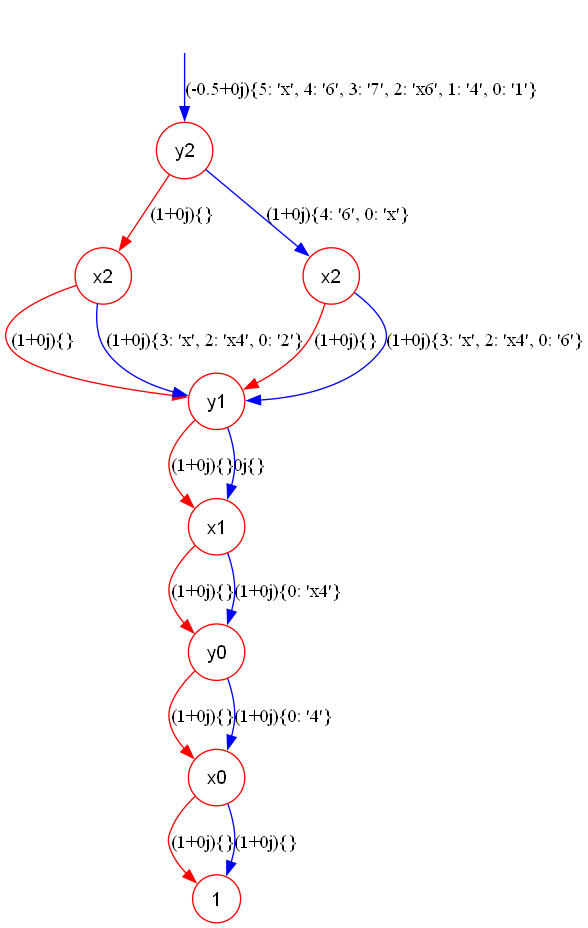

In [68]:
n=3
m=10*n

cir=gen_cir('Random_Clifford_T',n,m)
# cir=QuantumCircuit(2)
# cir.cx(0,1)
# cir.cx(1,0)
# cir.cx(0,1)
# cir.cx(1,0)
# for d in cir.data:
#     print(d)
tdd=simulate(cir,True)

tdd.show()

Done
Done


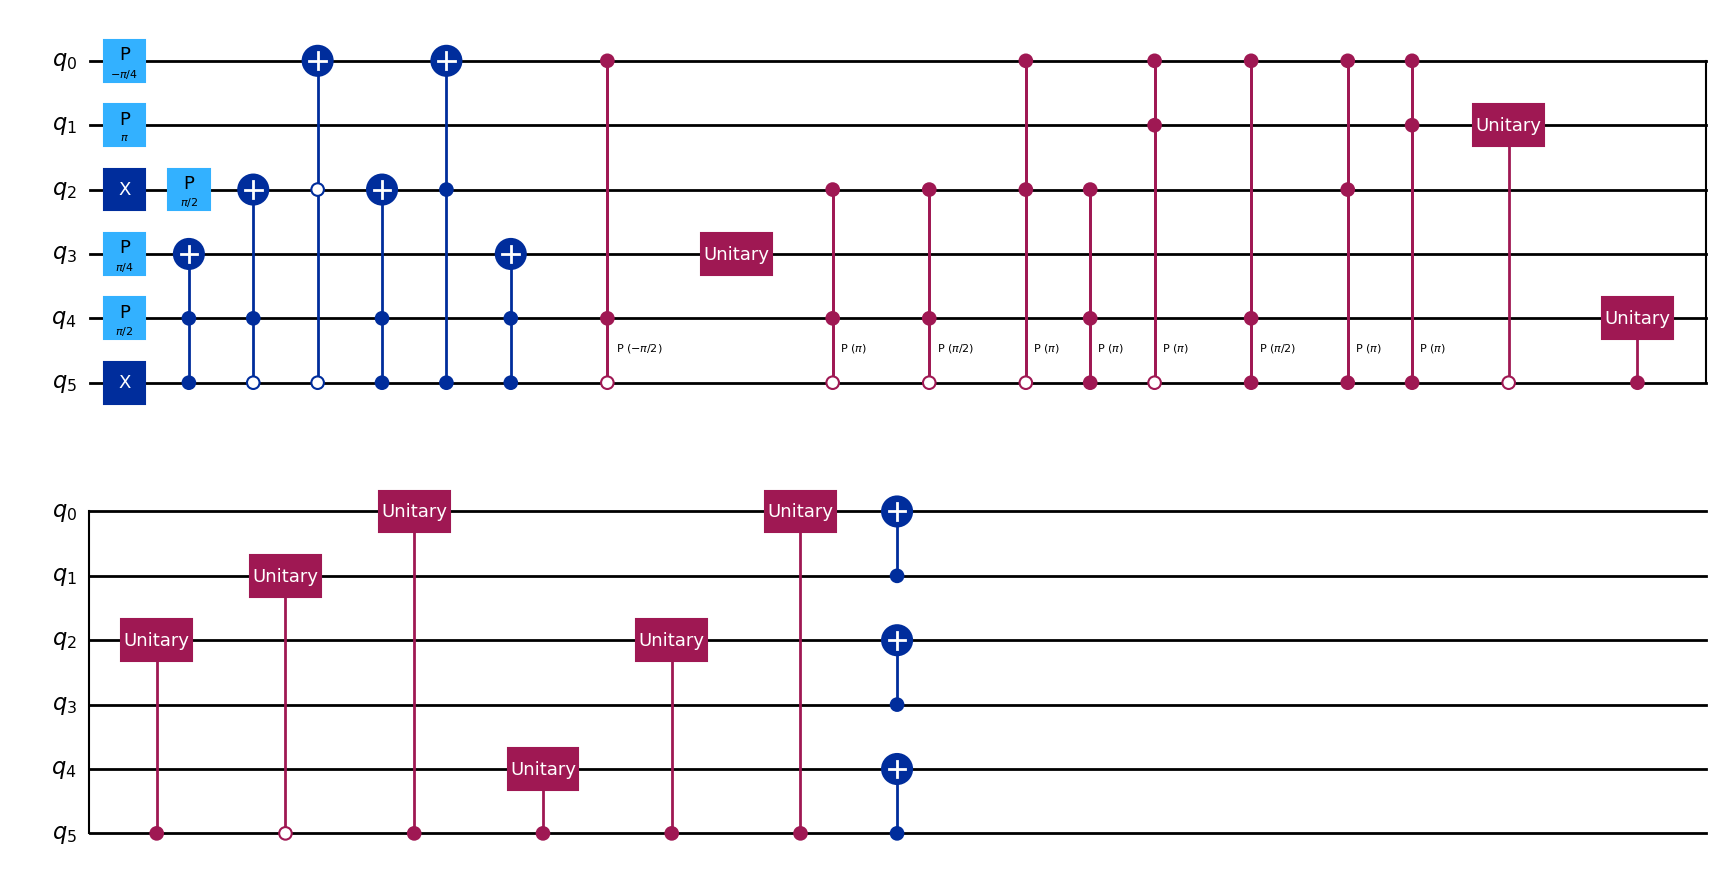

In [69]:
_,cir_s = to_zero_state(tdd,True)
print('Done')
cir_s_qis = cir_s.to_cir()
print('Done')
cir_s_qis.draw('mpl')

a 0.0005102157592773438
b 0.005921363830566406
c 0.0034034252166748047
d 0.0
e 0.0
a 0.0
b 0.0
c 0.0
d 0.0
e 0.0
a 0.0
b 0.0
c 0.0
d 0.0
e 0.0


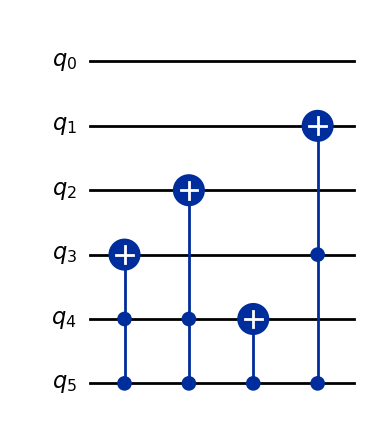

In [70]:
like_x = True
cir_syn,cir_head,cir_end = syn(cir_s)
# like_x = False
cir_syn,cir_head2,cir_end2 = syn(cir_syn)
# # like_x = True
cir_syn,cir_head2,cir_end2 = syn(cir_syn)
# # like_x = False
# cir_syn,cir_head2,cir_end2 = syn(cir_syn)
# cir_syn,cir_head2,cir_end2 = syn(cir_syn)
cir_syn.to_cir().draw('mpl')

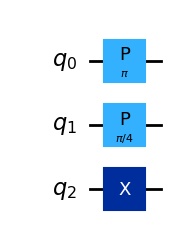

In [71]:
cir_head.to_cir().draw('mpl')
# print(cir_end)
cir_end.to_cir().draw('mpl')

a 0.0
b 0.0010242462158203125
c 0.0
d 0.0015506744384765625
e 0.0
a 0.0
b 0.0
c 0.0
d 0.0
e 0.0
a 0.0
b 0.004303693771362305
c 0.0
d 0.0
e 0.0


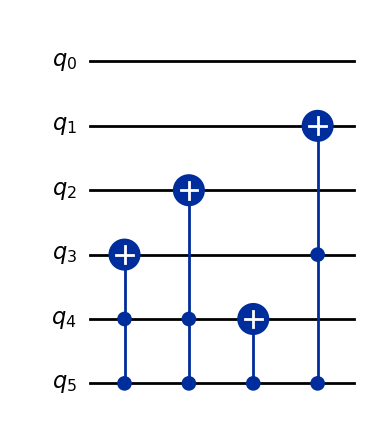

In [72]:
# for d in cir_syn.data:
    # print(d)
cir_syn,cir_head2,cir_end2 = syn(cir_syn)
cir_syn,cir_head2,cir_end2 = syn(cir_syn)
cir_syn,cir_head2,cir_end2 = syn(cir_syn)
cir_syn.to_cir().draw('mpl')

In [73]:
# cir = Circuit(3,[])
# g0 = Gate('x',{1:1},0)
# g1 = Gate('x',{2:1},0)
# g2 = Gate('x',{2:1},1)
# cir.data = [g0,g1,g2]
# G = to_H_Graph(cir)
# G = opt_H_Graph(G)
# cc = H_Graph_to_Cir(G)
# cc = H_Graph_to_Cir(G)
# cc.to_cir().draw()